# 6G JSCC: Bandwidth-Optimized Dual-Mode Architecture

This reproducible demonstration contrasts a **human mode** that transmits a Stable Diffusion VAE spatial latent for image reconstruction with a **machine mode** that transmits a learned 128-dimensional semantic vector for traffic-scene classification. Both modes are evaluated over an additive white Gaussian noise (AWGN) channel.

> **Research scope.** The digital curve in this notebook is an explanatory outage-threshold proxy, not a standards-compliant modem, source codec, or FEC simulation.

## 1. Environment setup and dependencies

The next cell installs only packages unavailable in the current kernel. If packages are newly installed, restart the kernel once and continue from this section.

In [1]:
import importlib.util
import subprocess
import sys

In [2]:
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from diffusers import AutoencoderKL
from sklearn.model_selection import train_test_split

SEED = 6
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / 'traffic_data'
FIGURE_DIR = PROJECT_DIR / 'results' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.is_dir(), f'Dataset directory not found: {DATA_DIR}'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 8 if DEVICE.type == 'cuda' else 2
TRAIN_BATCH_SIZE = 16 if DEVICE.type == 'cuda' else 4
EPOCHS = 50
LEARNING_RATE = 1e-3
SNR_LEVELS = [25, 20, 15, 10, 5, 0, -5]
QUALITATIVE_SNRS = [20, 10, 5, 0]
DIGITAL_OUTAGE_THRESHOLD_DB = 5
NUM_WORKERS = 0  # Portable across Windows/Jupyter environments.

sns.set_theme(style='whitegrid', context='paper', palette='colorblind')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 400, 'font.family': 'serif'})
print(f'Device: {DEVICE} | Dataset: {DATA_DIR}')

Device: cpu | Dataset: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\traffic_data


## 2. Data pipeline and custom-folder loading

`ImageFolder` maps each immediate subdirectory to one class. Inputs are resized to the VAE's required 512 × 512 resolution and normalized to the `[-1, 1]` range expected by the Stable Diffusion VAE.

Classes: ['highway', 'urban']
Total images: 200 | Train: 196 | Held-out test: 4
  highway: 124 total
  urban: 76 total


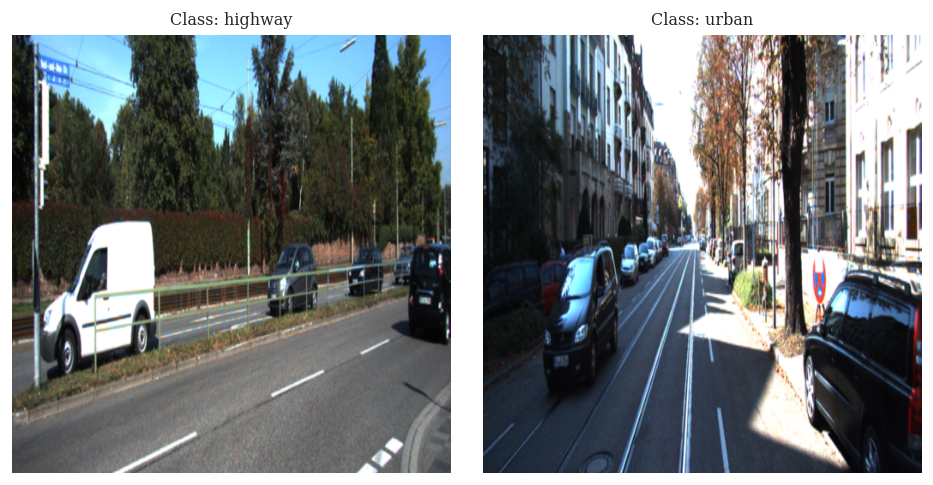

In [3]:
image_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])
dataset = datasets.ImageFolder(DATA_DIR, transform=image_transform)
class_names = dataset.classes
targets = np.asarray(dataset.targets)
num_classes = len(class_names)

train_indices, test_indices = train_test_split(
    np.arange(len(dataset)), test_size=0.02, stratify=targets, random_state=SEED
)
train_dataset, test_dataset = Subset(dataset, train_indices), Subset(dataset, test_indices)
train_loader = DataLoader(train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')

print('Classes:', class_names)
print(f'Total images: {len(dataset)} | Train: {len(train_dataset)} | Held-out test: {len(test_dataset)}')
for index, name in enumerate(class_names):
    print(f'  {name}: {(targets == index).sum()} total')

# Show one deterministic example from each class in the complete dataset.
fig, axes = plt.subplots(1, num_classes, figsize=(4 * num_classes, 4))
axes = np.atleast_1d(axes)
for class_id, ax in enumerate(axes):
    sample_index = int(np.where(targets == class_id)[0][0])
    image, label = dataset[sample_index]
    ax.imshow(((image.permute(1, 2, 0).numpy() + 1) / 2).clip(0, 1))
    ax.set_title(f'Class: {class_names[label]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Dual-branch models and AWGN channel core

The human branch uses a frozen pretrained VAE. The machine branch is trained from scratch on the traffic classes and is deliberately small: its transmitted representation is exactly 128 values per image.

In [4]:
VAE_MODEL_ID = 'stabilityai/sd-vae-ft-mse'
vae = AutoencoderKL.from_pretrained(VAE_MODEL_ID).to(DEVICE).eval()
for parameter in vae.parameters():
    parameter.requires_grad_(False)
VAE_SCALING_FACTOR = vae.config.scaling_factor
print(f'Loaded frozen VAE: {VAE_MODEL_ID}; scaling factor = {VAE_SCALING_FACTOR}')

class SemanticFeatureEncoder(nn.Module):
    """Lightweight image encoder: [B, 3, 512, 512] -> [B, 128]."""
    def __init__(self, feature_dim=128):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 24, kernel_size=5, stride=4, padding=2), nn.BatchNorm2d(24), nn.GELU(),
            nn.Conv2d(24, 48, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(48), nn.GELU(),
            nn.Conv2d(48, 96, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(96), nn.GELU(),
            nn.Conv2d(96, 128, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(128), nn.GELU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.projection = nn.Linear(128, feature_dim)

    def forward(self, images):
        features = self.backbone(images).flatten(1)
        return self.projection(features)

class MachineClassifierHead(nn.Module):
    """Task head: [B, 128] -> [B, num_classes] logits."""
    def __init__(self, num_classes, feature_dim=128):
        super().__init__()
        self.classifier = nn.Linear(feature_dim, num_classes)

    def forward(self, semantic_features):
        return self.classifier(semantic_features)

def simulate_awgn_channel(tensor, snr_db):
    """Add zero-mean AWGN at a target average signal-to-noise ratio in dB."""
    if not tensor.is_floating_point():
        raise TypeError('AWGN channel expects a floating-point tensor.')
    signal_power = tensor.detach().pow(2).mean()
    snr_linear = 10.0 ** (float(snr_db) / 10.0)
    noise_power = signal_power / snr_linear
    noise = torch.randn_like(tensor) * torch.sqrt(noise_power)
    return tensor + noise

semantic_encoder = SemanticFeatureEncoder().to(DEVICE)
machine_head = MachineClassifierHead(num_classes).to(DEVICE)

# Shape and channel sanity checks before training/evaluation.
sample_images, _ = next(iter(train_loader))
sample_images = sample_images[:min(2, len(sample_images))].to(DEVICE)
with torch.inference_mode():
    vae_latent = vae.encode(sample_images).latent_dist.mean * VAE_SCALING_FACTOR
    semantic_features = semantic_encoder(sample_images)
    logits = machine_head(semantic_features)
assert sample_images.shape[1:] == (3, 512, 512)
assert vae_latent.shape[1:] == (4, 64, 64), f'Unexpected VAE latent shape: {vae_latent.shape}'
assert semantic_features.shape == (sample_images.shape[0], 128)
assert logits.shape == (sample_images.shape[0], num_classes)

channel_probe = torch.randn(32, 128, device=DEVICE)
target_snr_db = 10.0
channel_output = simulate_awgn_channel(channel_probe, target_snr_db)
measured_snr_db = 10 * torch.log10(channel_probe.pow(2).mean() / (channel_output - channel_probe).pow(2).mean())
assert abs(measured_snr_db.item() - target_snr_db) < 1.5, 'AWGN power check failed.'
print('Shape checks passed. Empirical AWGN SNR:', f'{measured_snr_db.item():.2f} dB')

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.
C:\Users\Harshal\ML_Python\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loaded frozen VAE: stabilityai/sd-vae-ft-mse; scaling factor = 0.18215
Shape checks passed. Empirical AWGN SNR: 9.82 dB


## 4. AWGN-augmented machine-mode training

For each training batch, a single SNR is sampled uniformly from the evaluation set. Noise is injected into the transmitted 128-D representation before the classifier, creating a task-oriented and channel-aware semantic model. The held-out test partition is never used for optimization.

In [5]:
optimizer = torch.optim.AdamW(
    list(semantic_encoder.parameters()) + list(machine_head.parameters()),
    lr=LEARNING_RATE, weight_decay=1e-4
)
criterion = nn.CrossEntropyLoss()
train_history = []

for epoch in range(1, EPOCHS + 1):
    semantic_encoder.train()
    machine_head.train()
    epoch_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        sampled_snr = random.choice(SNR_LEVELS)
        optimizer.zero_grad(set_to_none=True)
        transmitted_features = semantic_encoder(images)
        received_features = simulate_awgn_channel(transmitted_features, sampled_snr)
        logits = machine_head(received_features)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    record = {'epoch': epoch, 'loss': epoch_loss / total, 'accuracy': 100 * correct / total}
    train_history.append(record)
    print(f"Epoch {epoch:02d}/{EPOCHS}: loss={record['loss']:.4f}, train accuracy={record['accuracy']:.1f}%")

assert all(not parameter.requires_grad for parameter in vae.parameters()), 'The pretrained VAE must remain frozen.'

Epoch 01/50: loss=0.5758, train accuracy=68.4%
Epoch 02/50: loss=0.4826, train accuracy=77.6%
Epoch 03/50: loss=0.4714, train accuracy=78.6%
Epoch 04/50: loss=0.4992, train accuracy=77.6%
Epoch 05/50: loss=0.4106, train accuracy=81.1%
Epoch 06/50: loss=0.4466, train accuracy=80.6%
Epoch 07/50: loss=0.4286, train accuracy=81.6%
Epoch 08/50: loss=0.3910, train accuracy=83.7%
Epoch 09/50: loss=0.3702, train accuracy=82.7%
Epoch 10/50: loss=0.3692, train accuracy=80.6%
Epoch 11/50: loss=0.3979, train accuracy=81.6%
Epoch 12/50: loss=0.3425, train accuracy=83.7%
Epoch 13/50: loss=0.4384, train accuracy=80.1%
Epoch 14/50: loss=0.3701, train accuracy=85.7%
Epoch 15/50: loss=0.3367, train accuracy=84.2%
Epoch 16/50: loss=0.3399, train accuracy=83.2%
Epoch 17/50: loss=0.3210, train accuracy=84.7%
Epoch 18/50: loss=0.3820, train accuracy=84.2%
Epoch 19/50: loss=0.2794, train accuracy=89.3%
Epoch 20/50: loss=0.2821, train accuracy=87.2%
Epoch 21/50: loss=0.2763, train accuracy=87.2%
Epoch 22/50: 

## 5. Quantitative evaluation across channel SNR

Human-mode MSE and PSNR are computed after mapping model-range images back to `[0, 1]`. Machine-mode accuracy is measured from noisy semantic vectors only on the held-out test split.

In [6]:
def to_display_range(images):
    return ((images + 1.0) / 2.0).clamp(0.0, 1.0)

@torch.inference_mode()
def evaluate_human_mode(snr_db):
    total_mse, total_psnr, total_images = 0.0, 0.0, 0
    for images, _ in test_loader:
        images = images.to(DEVICE)
        latent = vae.encode(images).latent_dist.mean * VAE_SCALING_FACTOR
        noisy_latent = simulate_awgn_channel(latent, snr_db)
        reconstructions = vae.decode(noisy_latent / VAE_SCALING_FACTOR).sample
        per_image_mse = (to_display_range(images) - to_display_range(reconstructions)).pow(2).flatten(1).mean(1)
        total_mse += per_image_mse.sum().item()
        total_psnr += (-10.0 * torch.log10(per_image_mse.clamp_min(1e-12))).sum().item()
        total_images += images.size(0)
    return total_mse / total_images, total_psnr / total_images

@torch.inference_mode()
def evaluate_machine_mode(snr_db):
    semantic_encoder.eval()
    machine_head.eval()
    correct, total = 0, 0
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        features = semantic_encoder(images)
        logits = machine_head(simulate_awgn_channel(features, snr_db))
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return 100.0 * correct / total

results = {'snr_db': [], 'mse': [], 'psnr_db': [], 'accuracy_pct': []}
for snr_db in SNR_LEVELS:
    mse, psnr = evaluate_human_mode(snr_db)
    accuracy = evaluate_machine_mode(snr_db)
    results['snr_db'].append(snr_db)
    results['mse'].append(mse)
    results['psnr_db'].append(psnr)
    results['accuracy_pct'].append(accuracy)
    print(f'SNR {snr_db:>3} dB | Human MSE: {mse:.6f} | PSNR: {psnr:.2f} dB | Machine accuracy: {accuracy:.2f}%')

assert len(results['snr_db']) == len(SNR_LEVELS)
assert all(0.0 <= value <= 100.0 for value in results['accuracy_pct'])

SNR  25 dB | Human MSE: 0.002922 | PSNR: 25.39 dB | Machine accuracy: 50.00%
SNR  20 dB | Human MSE: 0.003344 | PSNR: 24.81 dB | Machine accuracy: 50.00%
SNR  15 dB | Human MSE: 0.004565 | PSNR: 23.46 dB | Machine accuracy: 50.00%
SNR  10 dB | Human MSE: 0.008803 | PSNR: 20.63 dB | Machine accuracy: 50.00%
SNR   5 dB | Human MSE: 0.024003 | PSNR: 16.24 dB | Machine accuracy: 50.00%
SNR   0 dB | Human MSE: 0.068856 | PSNR: 11.65 dB | Machine accuracy: 50.00%
SNR  -5 dB | Human MSE: 0.128954 | PSNR: 8.90 dB | Machine accuracy: 50.00%


## 6. Bandwidth and transmission-overhead analysis

In [7]:
FLOAT32_BYTES = 4
payloads = {
    'Raw data': 512 * 512 * 3,
    'Human mode': 4 * 64 * 64,
    'Machine mode': 128,
}
raw_values = payloads['Raw data']
for name, values in payloads.items():
    payload_bytes = values * FLOAT32_BYTES
    saving_pct = 100 * (1 - values / raw_values)
    print(f'{name:13s}: {values:>8,} float32 values | {payload_bytes:>10,} bytes | saving vs. raw: {saving_pct:6.3f}%')

assert payloads['Raw data'] == 786_432
assert payloads['Human mode'] == 16_384
assert payloads['Machine mode'] == 128

Raw data     :  786,432 float32 values |  3,145,728 bytes | saving vs. raw:  0.000%
Human mode   :   16,384 float32 values |     65,536 bytes | saving vs. raw: 97.917%
Machine mode :      128 float32 values |        512 bytes | saving vs. raw: 99.984%


## 7. Research-grade publication plots

All figures are saved as high-resolution PNG and vector PDF files in `results/figures/`.

Saved: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\figures\figure1_qualitative_human_reconstructions.png


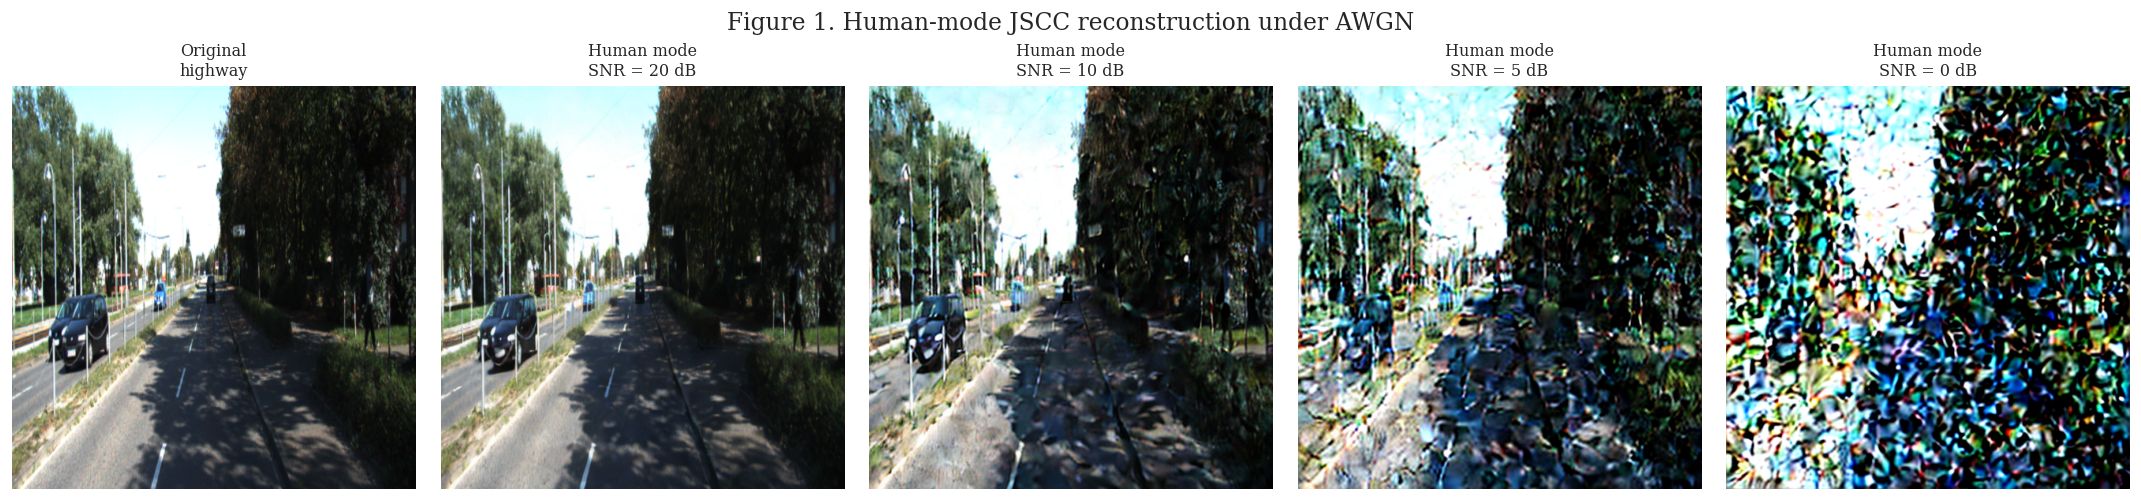

In [8]:
def save_figure(fig, stem):
    png_path = FIGURE_DIR / f'{stem}.png'
    pdf_path = FIGURE_DIR / f'{stem}.pdf'
    fig.savefig(png_path, bbox_inches='tight', dpi=400)
    fig.savefig(pdf_path, bbox_inches='tight')
    assert png_path.exists() and png_path.stat().st_size > 0
    assert pdf_path.exists() and pdf_path.stat().st_size > 0
    print(f'Saved: {png_path}')

@torch.inference_mode()
def human_reconstruction(images, snr_db):
    latent = vae.encode(images).latent_dist.mean * VAE_SCALING_FACTOR
    return vae.decode(simulate_awgn_channel(latent, snr_db) / VAE_SCALING_FACTOR).sample

# Figure 1: original and channel-impaired human-mode reconstructions.
test_image, test_label = test_dataset[0]
test_image = test_image.unsqueeze(0).to(DEVICE)
fig, axes = plt.subplots(1, 1 + len(QUALITATIVE_SNRS), figsize=(18, 4))
axes[0].imshow(to_display_range(test_image)[0].permute(1, 2, 0).cpu())
axes[0].set_title(f'Original\n{class_names[test_label]}')
axes[0].axis('off')
for ax, snr_db in zip(axes[1:], QUALITATIVE_SNRS):
    reconstruction = human_reconstruction(test_image, snr_db)
    ax.imshow(to_display_range(reconstruction)[0].permute(1, 2, 0).cpu())
    ax.set_title(f'Human mode\nSNR = {snr_db} dB')
    ax.axis('off')
fig.suptitle('Figure 1. Human-mode JSCC reconstruction under AWGN', y=1.03, fontsize=14)
plt.tight_layout()
save_figure(fig, 'figure1_qualitative_human_reconstructions')
plt.show()

Saved: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\figures\figure2_performance_vs_snr.png


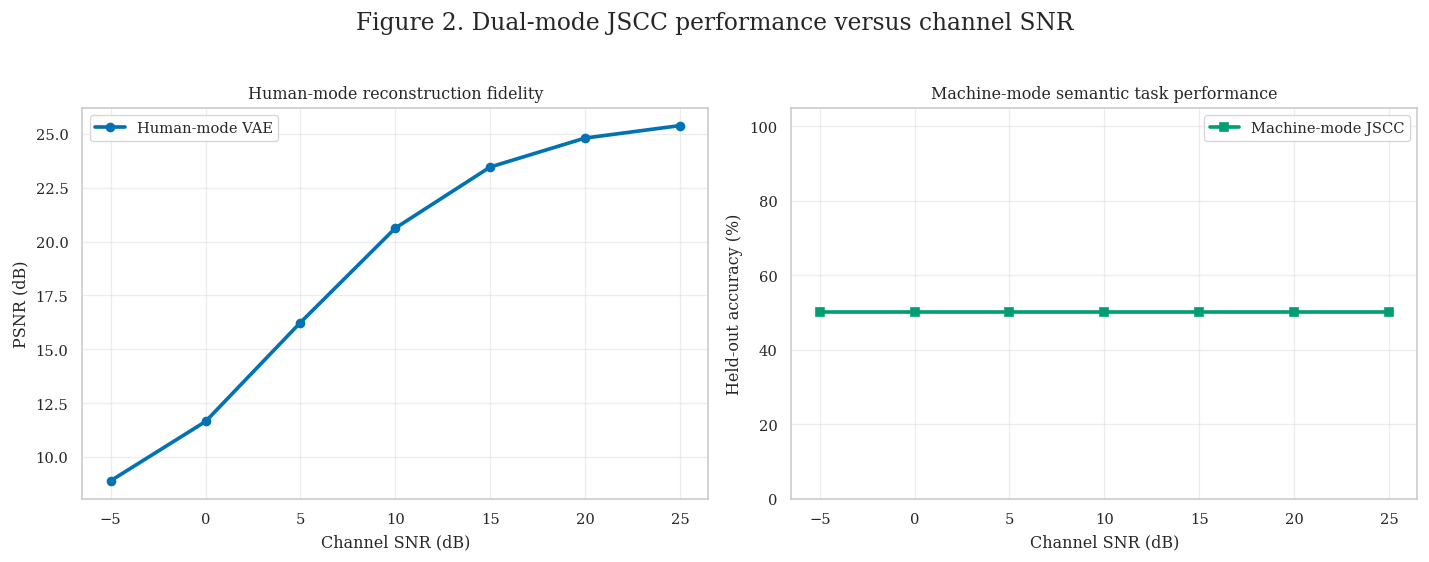

Saved: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\figures\figure3_jscc_vs_digital_cliff_effect.png


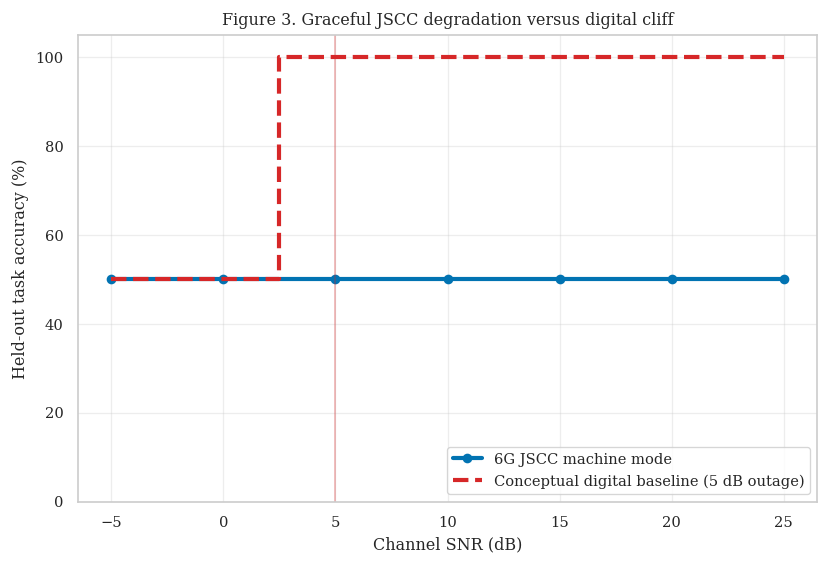

Saved: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\figures\figure4_bandwidth_comparison.png


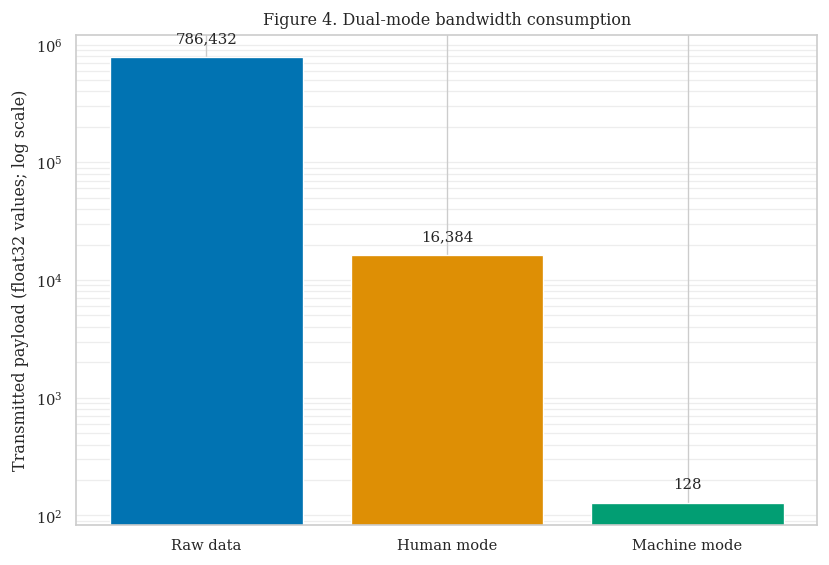

In [9]:
# Figure 2: quantitative human and machine performance.
plot_order = np.argsort(results['snr_db'])
plot_snr = np.asarray(results['snr_db'])[plot_order]
plot_psnr = np.asarray(results['psnr_db'])[plot_order]
plot_accuracy = np.asarray(results['accuracy_pct'])[plot_order]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(plot_snr, plot_psnr, marker='o', linewidth=2.2, label='Human-mode VAE')
axes[0].set(xlabel='Channel SNR (dB)', ylabel='PSNR (dB)', title='Human-mode reconstruction fidelity')
axes[0].grid(True, alpha=0.35)
axes[0].legend(frameon=True)
axes[1].plot(plot_snr, plot_accuracy, marker='s', linewidth=2.2, color=sns.color_palette('colorblind')[2], label='Machine-mode JSCC')
axes[1].set(xlabel='Channel SNR (dB)', ylabel='Held-out accuracy (%)', title='Machine-mode semantic task performance', ylim=(0, 105))
axes[1].grid(True, alpha=0.35)
axes[1].legend(frameon=True)
fig.suptitle('Figure 2. Dual-mode JSCC performance versus channel SNR', y=1.03, fontsize=14)
plt.tight_layout()
save_figure(fig, 'figure2_performance_vs_snr')
plt.show()

# Figure 3: transparent conceptual separation-based digital outage model.
chance_accuracy = 100.0 / num_classes
digital_accuracy = np.asarray([100.0 if snr >= DIGITAL_OUTAGE_THRESHOLD_DB else chance_accuracy for snr in plot_snr])
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(plot_snr, plot_accuracy, marker='o', linewidth=2.5, label='6G JSCC machine mode')
ax.step(plot_snr, digital_accuracy, where='mid', linewidth=2.5, linestyle='--', color='tab:red', label=f'Conceptual digital baseline ({DIGITAL_OUTAGE_THRESHOLD_DB} dB outage)')
ax.axvline(DIGITAL_OUTAGE_THRESHOLD_DB, color='tab:red', alpha=0.35, linewidth=1)
ax.set(xlabel='Channel SNR (dB)', ylabel='Held-out task accuracy (%)', title='Figure 3. Graceful JSCC degradation versus digital cliff', ylim=(0, 105))
ax.grid(True, alpha=0.35)
ax.legend(loc='best', frameon=True)
plt.tight_layout()
save_figure(fig, 'figure3_jscc_vs_digital_cliff_effect')
plt.show()

# Figure 4: float32 channel payload comparison.
fig, ax = plt.subplots(figsize=(7, 4.8))
bars = ax.bar(payloads.keys(), payloads.values(), color=sns.color_palette('colorblind', 3))
ax.set_yscale('log')
ax.set(ylabel='Transmitted payload (float32 values; log scale)', title='Figure 4. Dual-mode bandwidth consumption')
ax.grid(True, axis='y', alpha=0.35, which='both')
for bar, value in zip(bars, payloads.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, value * 1.25, f'{value:,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
save_figure(fig, 'figure4_bandwidth_comparison')
plt.show()

## Interpretation

Human mode preserves a spatial latent so that a pretrained generative decoder can reconstruct an image; its 16,384-value transmission is substantially smaller than raw pixels but much larger than machine mode. Machine mode transmits only 128 task-optimized values, providing a 99%+ payload reduction relative to raw float32 pixels. Its accuracy curve is meaningful only for the trained two-class task and local dataset.

The VAE was pretrained independently for visual reconstruction, whereas the semantic encoder and linear task head were trained locally with channel augmentation. The Figure 3 digital baseline is intentionally a conceptual outage model and should be replaced with a fully specified source/channel coding stack for standards-level comparisons.